# Online Retail Intelligence Capstone
## Notebook 03: Exploratory Data Analysis and Descriptive Statistics

### Project Overview

This notebook explores the cleaned Online Retail Transactions
dataset obtained from Kaggle.

**Dataset source:** [Kaggle – Online Retail Transactions Dataset](https://www.kaggle.com/datasets/abhishekrp1517/online-retail-transactions-dataset)

### Business Objectives

The exploratory analysis will investigate:

1. How retail sales performance varies over time.
2. Which products and geographic markets generate the most revenue.
3. How customers behave in terms of purchasing frequency and spending.
4. How descriptive statistics can reveal patterns, trends and outliers.

### Analytical Approach

The analysis will use Python, Pandas, NumPy, Matplotlib
and Seaborn to calculate business KPIs and visualise trends.

The cleaned datasets were generated in Notebook 02
using a documented ETL pipeline.

### Important Considerations

- Revenue represents positive sales-line value before refunds
  and other financial adjustments.
- CustomerID 15287 has been flagged for investigation.
- Customer-level findings will consider the potential impact
  of this unusually frequent identifier.
- The data covers historical transactions from 2010–2011.

### Expected Outputs

- Descriptive statistical summaries.
- Sales performance KPIs.
- Monthly revenue trends.
- Top-performing products and countries.
- Customer purchasing behaviour insights.
- Visualisations and business interpretations.

In [41]:
# STEP 1: Import libraries required for exploratory data analysis.
# Pandas supports data manipulation and descriptive statistics.
import pandas as pd

# NumPy supports numerical calculations.
import numpy as np

# Matplotlib and Seaborn support statistical visualisations.
import matplotlib.pyplot as plt
import seaborn as sns

# Path helps us locate project files across different folders.
from pathlib import Path

# STEP 2: Configure a consistent visualisation style.
# This improves chart readability throughout the notebook.
sns.set_theme(style="whitegrid")

# STEP 3: Configure Pandas display settings.
# Displaying more columns helps us inspect our datasets.
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:,.2f}".format)

print("EDA libraries imported successfully!")

EDA libraries imported successfully!


In [42]:
# STEP 4: Identify the project root directory.
# This works when the notebook runs from either the project
# root or the jupyter_notebooks folder.
project_root = Path.cwd().resolve()

if project_root.name == "jupyter_notebooks":
    project_root = project_root.parent

# STEP 5: Locate the cleaned datasets created in Notebook 02.
processed_dir = project_root / "data" / "processed"

sales_path = processed_dir / "retail_sales_clean.csv"
customer_path = processed_dir / "retail_customer_sales.csv"

# STEP 6: Check that both datasets exist before loading.
# This gives a clear error if Notebook 02 has not been run.
assert sales_path.exists(), f"Missing sales dataset: {sales_path}"
assert customer_path.exists(), f"Missing customer dataset: {customer_path}"

# STEP 7: Load the cleaned datasets.
# InvoiceNo and StockCode are identifiers, not numerical values.
# Explicit data types prevent mixed-type warnings.
df_sales = pd.read_csv(
    sales_path,
    dtype={
        "InvoiceNo": "string",
        "StockCode": "string"
    },
    parse_dates=["InvoiceDate"]
)

df_customer_sales = pd.read_csv(
    customer_path,
    dtype={
        "InvoiceNo": "string",
        "StockCode": "string"
    },
    parse_dates=["InvoiceDate"]
)

# STEP 8: Confirm the datasets loaded correctly.
print("Sales dataset shape:", df_sales.shape)
print("Customer dataset shape:", df_customer_sales.shape)

print("\nSales dataset preview:")
display(df_sales.head())

# STEP 9: Validate the loaded datasets.
# These checks ensure our EDA begins with the expected records.
assert len(df_sales) == 524878
assert len(df_customer_sales) == 392672

assert np.isclose(
    df_sales["Revenue"].sum(),
    10642110.80
)

print("\nEDA data loading validation: PASSED")

Sales dataset shape: (524878, 17)
Customer dataset shape: (392672, 17)

Sales dataset preview:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TransactionType,Revenue,InvoiceYear,InvoiceMonth,YearMonth,InvoiceDay,DayOfWeek,InvoiceHour,CustomerID_Flagged
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,Valid Sale,15.30,2010,12,2010-12,1,Wednesday,8,False
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,Valid Sale,20.34,2010,12,2010-12,1,Wednesday,8,False
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,Valid Sale,22.00,2010,12,2010-12,1,Wednesday,8,False
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,Valid Sale,20.34,2010,12,2010-12,1,Wednesday,8,False
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,Valid Sale,20.34,2010,12,2010-12,1,Wednesday,8,False



EDA data loading validation: PASSED


### Retail Sales Performance KPIs

This section calculates five key performance indicators (KPIs)
from the cleaned valid-sales dataset:

1. Total Sales Revenue
2. Total Orders
3. Average Order Value (AOV)
4. Total Units Sold
5. Unique Customers

These metrics provide an overview of historical retail
performance and establish a baseline for subsequent analysis.

Revenue represents positive sales-line value before
returns, refunds and other financial adjustments.

Customer counts are provisional because CustomerID 15287
has been flagged for further investigation.

In [43]:
# STEP 10: Calculate total sales revenue.
# Revenue is the sum of all valid sales-line values.
total_revenue = df_sales["Revenue"].sum()

# STEP 11: Calculate the number of distinct sales orders.
# One invoice may contain multiple product lines.
total_orders = df_sales["InvoiceNo"].nunique()

# STEP 12: Calculate Average Order Value (AOV).
# AOV measures the average revenue generated per distinct invoice.
average_order_value = total_revenue / total_orders

# STEP 13: Calculate the total number of units sold.
# Quantity represents the number of product units purchased.
total_units_sold = df_sales["Quantity"].sum()

# STEP 14: Calculate the number of unique customer identifiers.
# This is provisional because one identifier has been flagged.
unique_customers = df_sales["CustomerID"].nunique()

# STEP 15: Calculate the unique customers in the provisional
# customer-analysis dataset, excluding flagged CustomerID 15287.
unique_customers_provisional = (
    df_customer_sales["CustomerID"].nunique()
)

# STEP 16: Create a summary table for the business KPIs.
# A DataFrame makes the results easier to review and report.
kpi_summary = pd.DataFrame({
    "KPI": [
        "Total Sales Revenue",
        "Total Orders",
        "Average Order Value",
        "Total Units Sold",
        "Unique Customer IDs",
        "Provisional Unique Customer IDs"
    ],
    "Value": [
        total_revenue,
        total_orders,
        average_order_value,
        total_units_sold,
        unique_customers,
        unique_customers_provisional
    ]
})

# STEP 17: Validate the KPI calculations.
# Ensure the total revenue matches the validated ETL output.
assert np.isclose(total_revenue, 10642110.80)
assert total_orders > 0
assert average_order_value > 0
assert total_units_sold > 0

# STEP 18: Display the KPI summary.
print("RETAIL SALES PERFORMANCE KPIs")
display(kpi_summary)

print("\nKPI calculation validation: PASSED")

RETAIL SALES PERFORMANCE KPIs


,KPI,Value
0,Total Sales Revenue,"10,642,110.80"
1,Total Orders,"19,960.00"
2,Average Order Value,533.17
3,Total Units Sold,"5,572,420.00"
4,Unique Customer IDs,"4,338.00"
5,Provisional Unique Customer IDs,"4,337.00"



KPI calculation validation: PASSED


## Descriptive Statistics

This section examines the distribution of transaction quantities,
unit prices, revenue, and order values.

Descriptive statistics help identify typical purchasing behaviour,
variation in transaction values, and potential outliers.

The analysis uses valid sales transactions only.

In [44]:
# STEP 19: Select numerical variables for descriptive analysis.
# These variables help us understand sales quantities, prices,
# and revenue generated by individual transaction lines.
numerical_columns = [
    "Quantity",
    "UnitPrice",
    "Revenue"
]

# STEP 20: Calculate descriptive statistics.
# describe() provides count, mean, standard deviation,
# minimum, quartiles, and maximum values.
descriptive_stats = df_sales[numerical_columns].describe()

# STEP 21: Calculate additional statistics.
# Median and skewness help identify uneven distributions
# and the influence of unusually large transactions.
additional_stats = pd.DataFrame({
    "Median": df_sales[numerical_columns].median(),
    "Skewness": df_sales[numerical_columns].skew()
})

# STEP 22: Display descriptive statistics.
print("DESCRIPTIVE STATISTICS")
display(descriptive_stats.round(2))

print("\nADDITIONAL STATISTICS")
display(additional_stats.round(2))

# STEP 23: Validate the descriptive statistics.
# All selected variables should contain valid positive values.
assert (df_sales[numerical_columns] > 0).all().all()

print("\nDescriptive statistics validation: PASSED")

DESCRIPTIVE STATISTICS


,Quantity,UnitPrice,Revenue
count,"524,878.00","524,878.00","524,878.00"
mean,10.62,3.92,20.28
std,156.28,36.09,271.69
min,1.00,0.00,0.00
25%,1.00,1.25,3.90
50%,4.00,2.08,9.92
75%,11.00,4.13,17.70
max,"80,995.00","13,541.33","168,469.60"



ADDITIONAL STATISTICS


,Median,Skewness
Quantity,4.00,469.54
UnitPrice,2.08,205.09
Revenue,9.92,504.23



Descriptive statistics validation: PASSED


In [45]:
# STEP 24: Inspect the smallest positive prices and revenues.
# Values may display as 0.00 when rounded to two decimal places.

print("Minimum unit price (unrounded):", df_sales["UnitPrice"].min())
print("Minimum revenue (unrounded):", df_sales["Revenue"].min())

# Confirm that no zero or negative values remain.
print("Non-positive unit prices:", (df_sales["UnitPrice"] <= 0).sum())
print("Non-positive revenues:", (df_sales["Revenue"] <= 0).sum())

Minimum unit price (unrounded): 0.001
Minimum revenue (unrounded): 0.001
Non-positive unit prices: 0
Non-positive revenues: 0


### Order-Level Descriptive Statistics

Individual rows represent product lines rather than complete orders.

To understand customer purchasing behaviour, transaction lines are
aggregated by invoice number to calculate order revenue and total
units purchased per order.

These statistics help distinguish typical orders from unusually
large purchases.

In [46]:
# STEP 25: Aggregate product lines into complete customer orders.
# Each InvoiceNo represents one order containing one or more products.
order_summary = (
    df_sales.groupby("InvoiceNo", as_index=False)
    .agg(
        OrderRevenue=("Revenue", "sum"),
        OrderQuantity=("Quantity", "sum"),
        ProductLines=("StockCode", "size")
    )
)

# STEP 26: Calculate descriptive statistics for complete orders.
# These results describe typical order size and spending.
order_statistics = order_summary[
    ["OrderRevenue", "OrderQuantity", "ProductLines"]
].describe()

print("ORDER-LEVEL DESCRIPTIVE STATISTICS")
display(order_statistics.round(2))

# STEP 27: Compare average and median order values.
# Large orders can cause the average to exceed the median.
average_order_value = order_summary["OrderRevenue"].mean()
median_order_value = order_summary["OrderRevenue"].median()

print("\nTotal orders:", len(order_summary))
print("Average order value: £", round(average_order_value, 2))
print("Median order value: £", round(median_order_value, 2))

# STEP 28: Validate the invoice-level aggregation.
# Aggregating product lines must preserve total sales revenue.
assert len(order_summary) == df_sales["InvoiceNo"].nunique()

assert np.isclose(
    order_summary["OrderRevenue"].sum(),
    df_sales["Revenue"].sum()
)

print("\nOrder-level validation: PASSED")

ORDER-LEVEL DESCRIPTIVE STATISTICS


,OrderRevenue,OrderQuantity,ProductLines
count,"19,960.00","19,960.00","19,960.00"
mean,533.17,279.18,26.30
std,"1,780.41",955.01,47.29
min,0.38,1.00,1.00
25%,151.70,69.00,6.00
50%,303.30,150.00,15.00
75%,493.46,296.00,29.00
max,"168,469.60","80,995.00","1,114.00"



Total orders: 19960
Average order value: £ 533.17
Median order value: £ 303.3

Order-level validation: PASSED


### Distribution of Order Values

This visualisation examines how order revenue is distributed
across the retail dataset.

Because the descriptive statistics reveal exceptionally large
orders, the analysis uses the 99th percentile to focus the
visualisation on the majority of transactions.

The original data remains unchanged.

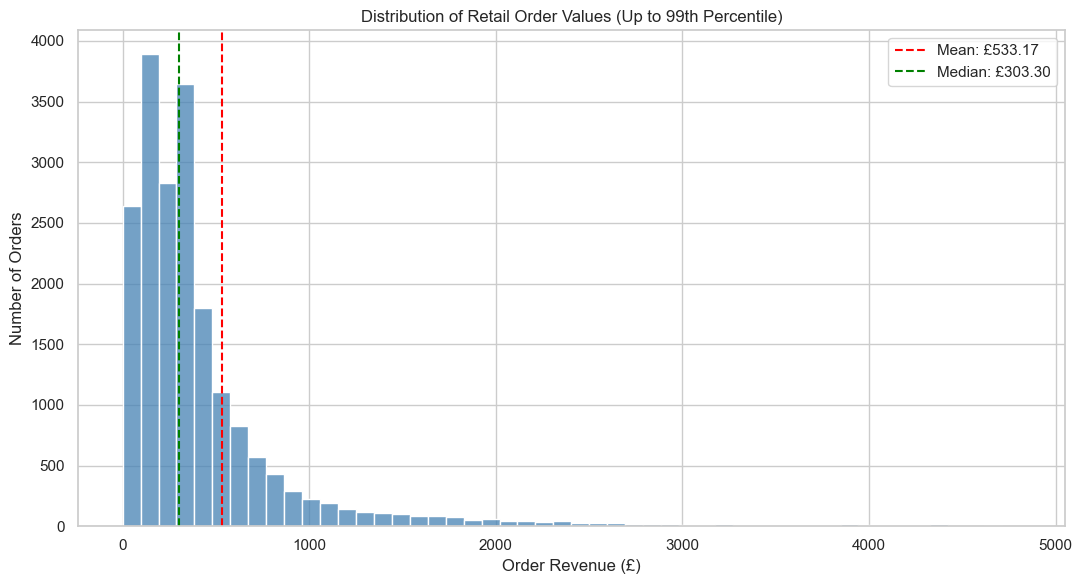

99th percentile threshold: £ 4821.17
Orders included in visualisation: 19760
Total orders: 19960
Orders above threshold: 200


In [47]:
# STEP 29: Calculate the 99th percentile of order revenue.
# This provides a visualisation threshold that limits the
# influence of exceptionally large orders on the chart.
revenue_99th_percentile = order_summary["OrderRevenue"].quantile(0.99)

# STEP 30: Create a subset for visualisation only.
# The full order_summary dataset remains unchanged.
order_plot_data = order_summary.loc[
    order_summary["OrderRevenue"] <= revenue_99th_percentile
].copy()

# STEP 31: Create a histogram of order values.
# The histogram shows the frequency of orders across revenue ranges.
plt.figure(figsize=(11, 6))

sns.histplot(
    data=order_plot_data,
    x="OrderRevenue",
    bins=50,
    color="steelblue"
)

# STEP 32: Add mean and median reference lines.
# These lines help compare typical orders with the overall average.
plt.axvline(
    average_order_value,
    color="red",
    linestyle="--",
    label=f"Mean: £{average_order_value:,.2f}"
)

plt.axvline(
    median_order_value,
    color="green",
    linestyle="--",
    label=f"Median: £{median_order_value:,.2f}"
)

# STEP 33: Format the chart for business interpretation.
plt.title("Distribution of Retail Order Values (Up to 99th Percentile)")
plt.xlabel("Order Revenue (£)")
plt.ylabel("Number of Orders")
plt.legend()
plt.tight_layout()

# STEP 34: Display the chart.
plt.show()

# STEP 35: Report how many orders are included in the chart.
print("99th percentile threshold: £", round(revenue_99th_percentile, 2))
print("Orders included in visualisation:", len(order_plot_data))
print("Total orders:", len(order_summary))
print("Orders above threshold:", len(order_summary) - len(order_plot_data))

### Key Findings: Order Value Distribution

The distribution of retail order values is strongly right-skewed.

The average order value (£533.17) is considerably higher than the
median (£303.30), indicating that high-value orders influence
the overall average.

Most orders are concentrated within the lower revenue ranges,
while a smaller proportion generates substantially higher revenue.

**Business implication:** Retail managers should consider both
average and median order values when assessing sales performance.
High-value orders may also warrant separate investigation to
understand their contribution to revenue.

**Limitation:** The chart displays orders up to the 99th percentile
for readability. The full dataset was retained for KPI calculations.

## Monthly Sales Performance

This section examines how revenue and order volumes change over time.

Monthly aggregation helps identify sales trends, seasonal patterns,
and periods of unusually high or low business activity.

In [48]:
# STEP 36: Aggregate sales revenue and order volume by month.
# Each month is represented using the YearMonth feature
# created during the data-cleaning stage.
monthly_sales = (
    df_sales.groupby("YearMonth", as_index=False)
    .agg(
        TotalRevenue=("Revenue", "sum"),
        TotalOrders=("InvoiceNo", "nunique"),
        UnitsSold=("Quantity", "sum")
    )
    .sort_values("YearMonth")
)

# STEP 37: Calculate monthly average order value.
# This measures average revenue generated per invoice each month.
monthly_sales["AverageOrderValue"] = (
    monthly_sales["TotalRevenue"] / monthly_sales["TotalOrders"]
)

# STEP 38: Validate the monthly aggregation.
# Monthly revenue must reconcile with total valid-sales revenue.
assert np.isclose(
    monthly_sales["TotalRevenue"].sum(),
    df_sales["Revenue"].sum()
)

# STEP 39: Display the monthly sales performance table.
print("MONTHLY SALES PERFORMANCE")
display(monthly_sales.round(2))

print("\nMonthly revenue validation: PASSED")

MONTHLY SALES PERFORMANCE


,YearMonth,TotalRevenue,TotalOrders,UnitsSold,AverageOrderValue
0,2010-12,"821,452.73",1559,358019,526.91
1,2011-01,"689,811.61",1086,387099,635.19
2,2011-02,"522,545.56",1100,282934,475.04
3,2011-03,"716,215.26",1454,376599,492.58
4,2011-04,"536,968.49",1246,307953,430.95
5,2011-05,"769,296.61",1681,395001,457.64
6,2011-06,"760,547.01",1533,388511,496.12
7,2011-07,"718,076.12",1475,399693,486.83
8,2011-08,"757,841.38",1361,421020,556.83
9,2011-09,"1,056,435.19",1837,569573,575.09



Monthly revenue validation: PASSED


### Key Findings: Monthly Sales Performance

Monthly revenue varied considerably throughout the observation period.

November 2011 recorded the highest revenue (£1,503,866.78)
and the greatest order volume (2,769 orders).

Revenue increased between September and November 2011,
suggesting stronger retail activity towards the end of the year.

February 2011 recorded the lowest revenue among complete months
(£522,545.56).

**Business implication:** Retail managers could investigate the
drivers of stronger late-year sales and use these findings to
inform inventory planning, marketing campaigns, and staffing.

**Limitation:** December 2011 is incomplete, covering only
1–9 December. It should not be compared directly with complete months.

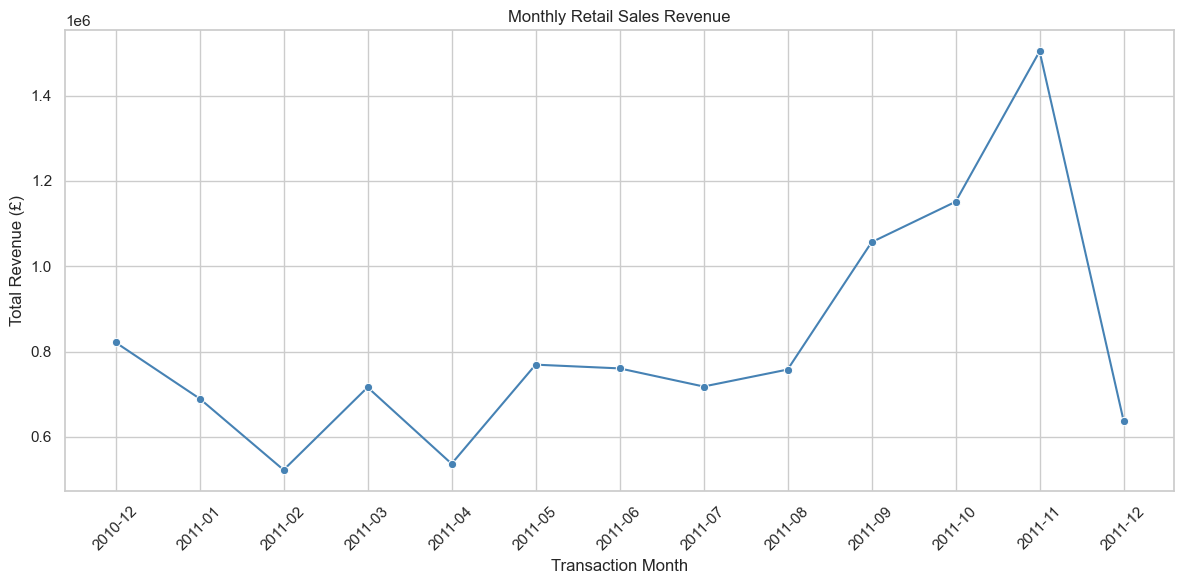

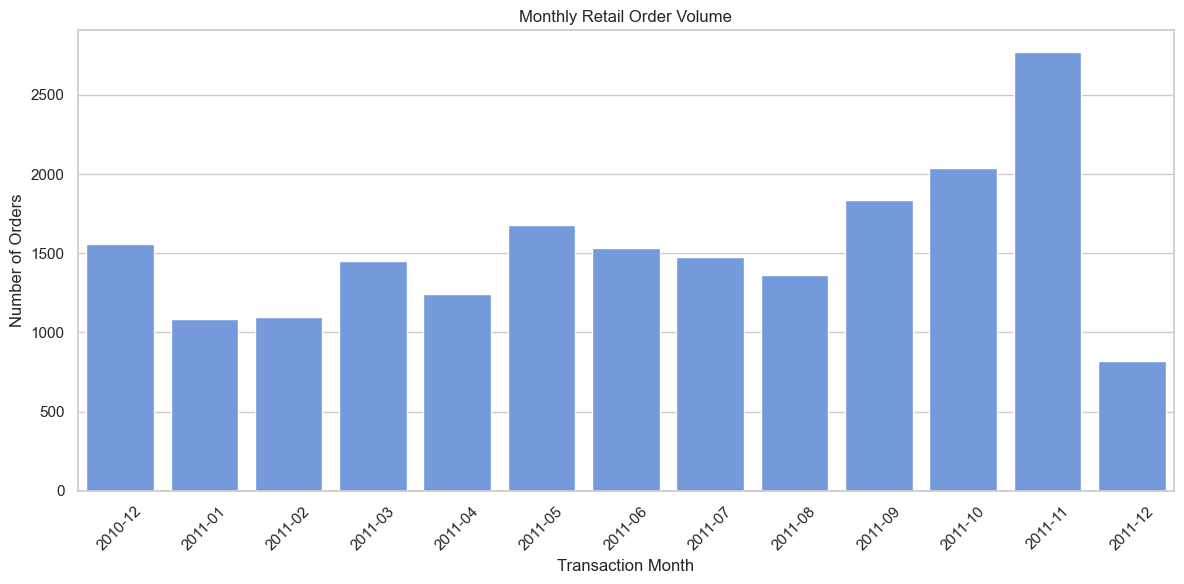

Monthly visualisation validation: PASSED


In [49]:
# STEP 40: Prepare monthly data for visualisation.
# Convert YearMonth to text so the x-axis displays month labels.
monthly_plot = monthly_sales.copy()
monthly_plot["YearMonth"] = monthly_plot["YearMonth"].astype(str)

# STEP 41: Create a monthly revenue line chart.
# This helps identify changes in sales performance over time.
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=monthly_plot,
    x="YearMonth",
    y="TotalRevenue",
    marker="o",
    color="steelblue"
)

# STEP 42: Format the monthly revenue chart.
plt.title("Monthly Retail Sales Revenue")
plt.xlabel("Transaction Month")
plt.ylabel("Total Revenue (£)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# STEP 43: Create a monthly order volume bar chart.
# This shows how customer order activity changes over time.
plt.figure(figsize=(12, 6))

sns.barplot(
    data=monthly_plot,
    x="YearMonth",
    y="TotalOrders",
    color="cornflowerblue"
)

# STEP 44: Format the order volume chart.
plt.title("Monthly Retail Order Volume")
plt.xlabel("Transaction Month")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# STEP 45: Validate that the monthly dataset is complete.
# The dataset covers 13 distinct calendar months.
assert len(monthly_plot) == 13

print("Monthly visualisation validation: PASSED")

### Key Findings: Monthly Revenue and Order Volume

The monthly revenue and order volume charts reveal a substantial
increase in retail activity between August and November 2011.

November 2011 recorded the highest revenue (£1,503,866.78)
and the highest number of orders (2,769).

The simultaneous increase in revenue and order volume suggests
that higher purchasing activity contributed significantly to
overall revenue growth.

**Business implication:** The retailer could investigate the
drivers of increased late-year demand and use the findings to
support inventory planning, staffing, and marketing decisions.

**Limitation:** December 2011 contains only nine days of
transaction data and is therefore not directly comparable
with complete months.

## Product Sales Performance

This section identifies the products generating the highest
sales revenue.

Products are ranked using revenue rather than quantity alone,
because selling more units does not necessarily mean generating
more revenue.

In [50]:
# STEP 46: Aggregate sales performance by product.
# StockCode identifies products, while Description provides
# a readable product name for reporting.
product_sales = (
    df_sales.groupby("StockCode", as_index=False)
    .agg(
        Description=("Description", "first"),
        TotalRevenue=("Revenue", "sum"),
        UnitsSold=("Quantity", "sum"),
        TotalOrders=("InvoiceNo", "nunique")
    )
)

# STEP 47: Rank products by total revenue.
# Higher-revenue products appear first.
product_sales = product_sales.sort_values(
    "TotalRevenue",
    ascending=False
)

# STEP 48: Select the ten highest-revenue products.
top_10_products = product_sales.head(10).copy()

print("TOP 10 PRODUCTS BY SALES REVENUE")
display(top_10_products.round(2))

# STEP 49: Validate product-level revenue aggregation.
# Total revenue across products should equal total sales revenue.
assert np.isclose(
    product_sales["TotalRevenue"].sum(),
    df_sales["Revenue"].sum()
)

print("\nProduct revenue validation: PASSED")

TOP 10 PRODUCTS BY SALES REVENUE


,StockCode,Description,TotalRevenue,UnitsSold,TotalOrders
3911,DOT,DOTCOM POSTAGE,"206,248.77",706,706
1310,22423,REGENCY CAKESTAND 3 TIER,"174,156.54",13851,1988
2465,23843,"PAPER CRAFT , LITTLE BIRDIE","168,469.60",80995,1
3407,85123A,WHITE HANGING HEART T-LIGHT HOLDER,"104,462.75",37641,2198
2670,47566,PARTY BUNTING,"99,445.23",18283,1685
3387,85099B,JUMBO BAG RED RETROSPOT,"94,159.81",48371,2089
2020,23166,MEDIUM CERAMIC TOP STORAGE JAR,"81,700.92",78033,247
3914,POST,POSTAGE,"78,101.88",3150,1126
3912,M,Manual,"77,750.27",6984,289
1942,23084,RABBIT NIGHT LIGHT,"66,870.03",30739,994



Product revenue validation: PASSED


### Identifying Merchandise and Non-Merchandise Revenue

The initial product ranking includes postage and manual
transaction charges.

To produce a more meaningful product performance analysis,
known non-merchandise codes are separated from merchandise.

The original valid-sales dataset remains unchanged.

This classification is provisional because other special
stock codes may require investigation.

In [51]:
# STEP 50: Identify # Known non-merchandise codes identified through stock-code review.
# DOT and POST represent postage-related charges.
# M represents manual entries.
# AMAZONFEE represents platform fees.
# B represents a bad-debt accounting adjustment.
# S (samples) remains under review and is not excluded yet.
non_merchandise_codes = [
    "DOT",
    "POST",
    "M",
    "AMAZONFEE",
    "B"
]

# STEP 51: Create a provisional merchandise dataset.
# Keep the original df_sales unchanged for reconciliation.
df_merchandise = df_sales.loc[
    ~df_sales["StockCode"].astype(str).str.upper().isin(
        non_merchandise_codes
    )
].copy()

# STEP 52: Create a separate dataset of flagged charges.
# These transactions remain available for investigation.
df_non_merchandise = df_sales.loc[
    df_sales["StockCode"].astype(str).str.upper().isin(
        non_merchandise_codes
    )
].copy()

# STEP 53: Recalculate product performance using merchandise only.
merchandise_sales = (
    df_merchandise.groupby("StockCode", as_index=False)
    .agg(
        Description=("Description", "first"),
        TotalRevenue=("Revenue", "sum"),
        UnitsSold=("Quantity", "sum"),
        TotalOrders=("InvoiceNo", "nunique")
    )
    .sort_values("TotalRevenue", ascending=False)
)

# STEP 54: Display the revised top 10 products.
top_10_merchandise = merchandise_sales.head(10).copy()

print("TOP 10 MERCHANDISE PRODUCTS BY REVENUE")
display(top_10_merchandise.round(2))

# STEP 55: Validate the separation.
# All original valid-sales rows and revenue must be accounted for.
assert len(df_merchandise) + len(df_non_merchandise) == len(df_sales)

assert np.isclose(
    df_merchandise["Revenue"].sum()
    + df_non_merchandise["Revenue"].sum(),
    df_sales["Revenue"].sum()
)

print("\nMerchandise revenue:",
      round(df_merchandise["Revenue"].sum(), 2))

print("Flagged non-merchandise revenue:",
      round(df_non_merchandise["Revenue"].sum(), 2))

print("Revenue reconciliation: PASSED")

TOP 10 MERCHANDISE PRODUCTS BY REVENUE


,StockCode,Description,TotalRevenue,UnitsSold,TotalOrders
1310,22423,REGENCY CAKESTAND 3 TIER,"174,156.54",13851,1988
2465,23843,"PAPER CRAFT , LITTLE BIRDIE","168,469.60",80995,1
3407,85123A,WHITE HANGING HEART T-LIGHT HOLDER,"104,462.75",37641,2198
2670,47566,PARTY BUNTING,"99,445.23",18283,1685
3387,85099B,JUMBO BAG RED RETROSPOT,"94,159.81",48371,2089
2020,23166,MEDIUM CERAMIC TOP STORAGE JAR,"81,700.92",78033,247
1942,23084,RABBIT NIGHT LIGHT,"66,870.03",30739,994
1006,22086,PAPER CHAIN KIT 50'S CHRISTMAS,"64,875.59",19329,1160
3194,84879,ASSORTED COLOUR BIRD ORNAMENT,"58,927.62",36362,1455
2845,79321,CHILLI LIGHTS,"54,096.36",10302,661



Merchandise revenue: 10255184.18
Flagged non-merchandise revenue: 386926.62
Revenue reconciliation: PASSED


### Review of Special Stock Codes

The initial merchandise classification excludes known postage
and manual-entry codes.

This section investigates other stock codes containing no digits
to identify possible service charges or adjustment records.

This is a screening method rather than a definitive classification.

In [52]:
# STEP 56: Standardise stock codes for inspection.
# This avoids differences caused by whitespace or letter case.
stock_codes = (
    df_merchandise["StockCode"]
    .astype("string")
    .str.strip()
    .str.upper()
)

# STEP 57: Flag codes that contain no numerical characters.
# Such codes may represent charges, discounts or adjustments.
# This is only a screening rule; it does not prove a code is non-merchandise.
special_code_mask = (
    stock_codes.str.fullmatch(r"[A-Z]+", na=False)
    .fillna(False)
    .astype(bool)
)

# STEP 58: Summarise flagged codes and their revenue.
special_code_review = (
    df_merchandise.loc[special_code_mask]
    .groupby(["StockCode", "Description"], dropna=False)
    .agg(
        TransactionRows=("InvoiceNo", "size"),
        TotalRevenue=("Revenue", "sum")
    )
    .reset_index()
    .sort_values("TotalRevenue", ascending=False)
)

# STEP 59: Display potential special stock codes.
print("ADDITIONAL SPECIAL STOCK CODES FOR REVIEW")
display(special_code_review.round(2))

print(
    "\nNumber of flagged transaction rows:",
    special_code_mask.sum()
)

ADDITIONAL SPECIAL STOCK CODES FOR REVIEW


,StockCode,Description,TransactionRows,TotalRevenue
0,DCGSSBOY,BOYS PARTY BAG,11,150.55
1,DCGSSGIRL,GIRLS PARTY BAG,13,144.43
3,S,SAMPLES,2,63.05
2,PADS,PADS TO MATCH ALL CUSHIONS,3,0.00



Number of flagged transaction rows: 29


### Merchandise Classification Decisions

An additional review of alphabetic stock codes identified
platform fees, accounting adjustments, samples and genuine products.

The following codes are excluded from merchandise revenue:
- DOT: Postage-related charge
- POST: Postage
- M: Manual entry
- AMAZONFEE: Amazon platform fee
- B: Bad-debt adjustment

Codes DCGSSBOY, DCGSSGIRL and PADS are retained because their
descriptions indicate physical merchandise.

Code S (SAMPLES) remains provisionally included pending further
review.

This classification is based on available transaction descriptions
and is subject to the limitations of the historical dataset.

### Top 10 Merchandise Products by Revenue

This visualisation identifies the merchandise products generating
the highest sales revenue.

Non-merchandise charges such as postage, manual adjustments,
platform fees and bad-debt adjustments are excluded.

The analysis also highlights unusually large transactions
that may influence product revenue rankings.

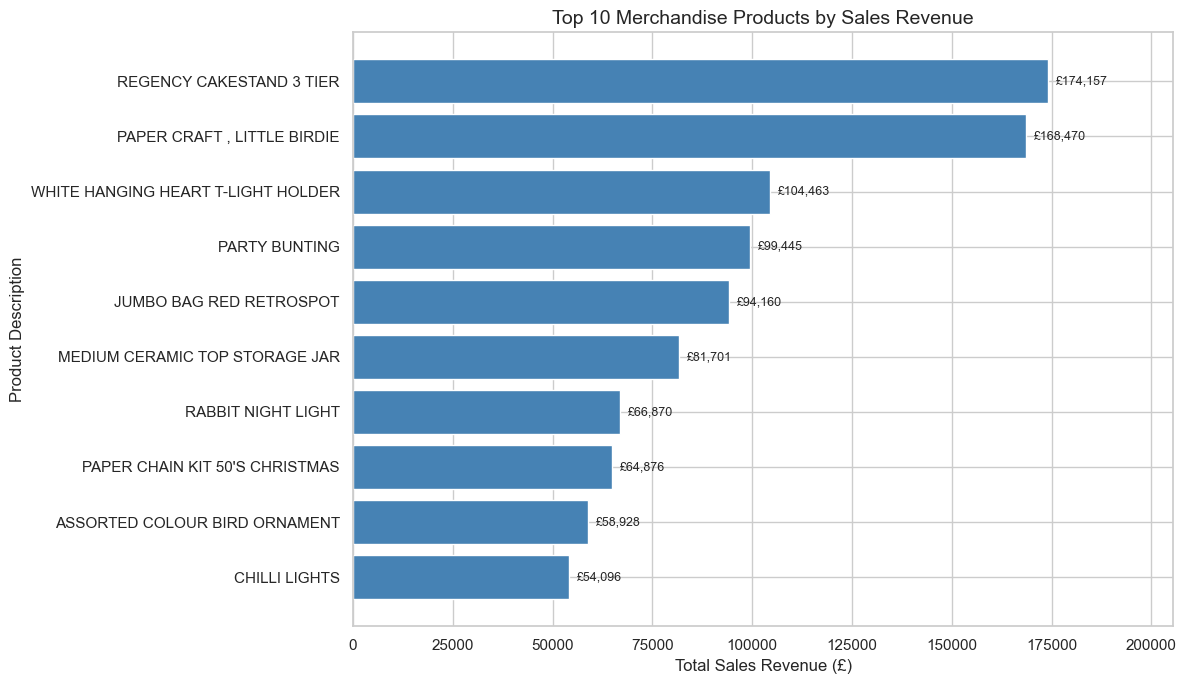

In [53]:
# STEP 60: Prepare the top 10 merchandise products for visualisation.
# Use the previously calculated top 10 merchandise table.
# Sort in ascending order so the highest-revenue product appears at the top.

top_products_plot = top_10_merchandise.sort_values(
    by="TotalRevenue",
    ascending=True
)

# STEP 61: Create a horizontal bar chart of merchandise revenue.
# Horizontal bars make longer product descriptions easier to read.

plt.figure(figsize=(12, 7))

bars = plt.barh(
    top_products_plot["Description"],
    top_products_plot["TotalRevenue"],
    color="steelblue"
)

# STEP 62: Format the chart for business interpretation.
plt.title(
    "Top 10 Merchandise Products by Sales Revenue",
    fontsize=14
)
plt.xlabel("Total Sales Revenue (£)")
plt.ylabel("Product Description")

# STEP 63: Add revenue labels to the end of each bar.
for bar in bars:
    revenue = bar.get_width()

    plt.text(
        revenue + 2000,
        bar.get_y() + bar.get_height() / 2,
        f"£{revenue:,.0f}",
        va="center",
        fontsize=9
    )

plt.xlim(0, top_products_plot["TotalRevenue"].max() * 1.18)
plt.tight_layout()
plt.show()

### Product Revenue Analysis: Key Findings

The product revenue analysis identifies the merchandise items contributing most to retail sales, excluding identified postage charges, platform fees and accounting adjustments.

**Key findings:**

1. **Highest-revenue product:** REGENCY CAKESTAND 3 TIER generated £174,156.54 across 1,988 orders, indicating broad purchasing activity.

2. **Exceptional transaction:** PAPER CRAFT, LITTLE BIRDIE generated £168,469.60 from a single order involving 80,995 units. This unusually large transaction may distort product rankings and should be investigated before drawing conclusions about sustained demand.

3. **Frequently purchased product:** WHITE HANGING HEART T-LIGHT HOLDER generated £104,462.75 across 2,198 orders, demonstrating sales activity across many transactions.

**Business implications:**

The retailer could prioritise consistently purchased, high-revenue products when planning inventory and promotions. However, exceptional bulk transactions should be distinguished from recurring customer demand.

**Limitation:** Revenue rankings do not represent profitability because product costs and profit margins are unavailable.

In [54]:
# STEP 64: Verify the updated merchandise revenue reconciliation.
# Merchandise and non-merchandise revenue must sum to total valid-sales revenue.

print("Total valid-sales revenue:", round(df_sales["Revenue"].sum(), 2))
print("Merchandise revenue:", round(df_merchandise["Revenue"].sum(), 2))
print(
    "Non-merchandise revenue:",
    round(df_sales["Revenue"].sum() - df_merchandise["Revenue"].sum(), 2)
)

# Confirm that the revenue split is mathematically consistent.
assert np.isclose(
    df_sales["Revenue"].sum(),
    df_merchandise["Revenue"].sum()
    + (df_sales["Revenue"].sum() - df_merchandise["Revenue"].sum())
)

print("Revenue reconciliation: PASSED")

Total valid-sales revenue: 10642110.8
Merchandise revenue: 10255184.18
Non-merchandise revenue: 386926.62
Revenue reconciliation: PASSED


## Geographic Sales Performance Analysis

### Business Question 2: Which geographic markets contribute most to revenue?

This section examines the geographic distribution of retail sales
using the Country field in the cleaned dataset.

The analysis aims to:

- Identify countries generating the highest sales revenue.
- Compare sales revenue, order volume and units sold across markets.
- Determine the United Kingdom's contribution to overall revenue.
- Highlight opportunities for market development.

The analysis uses the valid-sales dataset, including separately
classified non-merchandise charges, to remain consistent with
the previously reported overall sales KPIs.


In [55]:
# STEP 65: Group valid sales transactions by country.
# Calculate total revenue, distinct orders, units sold and
# distinct customer IDs for each geographic market.

country_performance = (
    df_sales.groupby("Country")
    .agg(
        TotalRevenue=("Revenue", "sum"),
        TotalOrders=("InvoiceNo", "nunique"),
        UnitsSold=("Quantity", "sum"),
        UniqueCustomers=("CustomerID", "nunique")
    )
    .reset_index()
)


# STEP 66: Calculate average order value for each country.
# Average Order Value = Total Revenue / Total Orders.

country_performance["AverageOrderValue"] = (
    country_performance["TotalRevenue"]
    / country_performance["TotalOrders"]
)


# STEP 67: Calculate each country's percentage contribution
# to overall valid-sales revenue.

total_sales_revenue = df_sales["Revenue"].sum()

country_performance["RevenueSharePct"] = (
    country_performance["TotalRevenue"]
    / total_sales_revenue
    * 100
)


# STEP 68: Rank countries by revenue and validate the results.
# Revenue totals should reconcile with the original sales dataset.

country_performance = (
    country_performance
    .sort_values("TotalRevenue", ascending=False)
    .reset_index(drop=True)
)

# Check that country revenue totals equal total sales revenue.
assert np.isclose(
    country_performance["TotalRevenue"].sum(),
    total_sales_revenue
)

# Check that country revenue shares add up to 100%.
assert np.isclose(
    country_performance["RevenueSharePct"].sum(),
    100
)

print("TOP 10 COUNTRIES BY SALES REVENUE")

display(
    country_performance.head(10).round(2)
)

print("\nNumber of countries:", len(country_performance))

print(
    "Total geographic revenue:",
    round(country_performance["TotalRevenue"].sum(), 2)
)

print("\nGeographic revenue validation: PASSED")

TOP 10 COUNTRIES BY SALES REVENUE


,Country,TotalRevenue,TotalOrders,UnitsSold,UniqueCustomers,AverageOrderValue,RevenueSharePct
0,United Kingdom,"9,001,744.09",18019,4646906,3920,499.57,84.59
1,Netherlands,"285,446.34",94,200361,9,"3,036.66",2.68
2,EIRE,"283,140.52",288,147007,4,983.13,2.66
3,Germany,"228,678.40",457,119154,94,500.39,2.15
4,France,"209,625.37",392,112060,88,534.76,1.97
5,Australia,"138,453.81",57,83891,9,"2,429.01",1.30
6,Spain,"61,558.56",90,27933,30,683.98,0.58
7,Switzerland,"57,067.60",54,30617,22,"1,056.81",0.54
8,Belgium,"41,196.34",98,23237,25,420.37,0.39
9,Sweden,"38,367.83",36,36078,8,"1,065.77",0.36



Number of countries: 38
Total geographic revenue: 10642110.8

Geographic revenue validation: PASSED


### Geographic Revenue Distribution

This visualisation compares the ten highest-revenue countries
and highlights the concentration of sales in the United Kingdom.

Revenue is calculated from valid sales transactions, including
the separately classified non-merchandise charges.

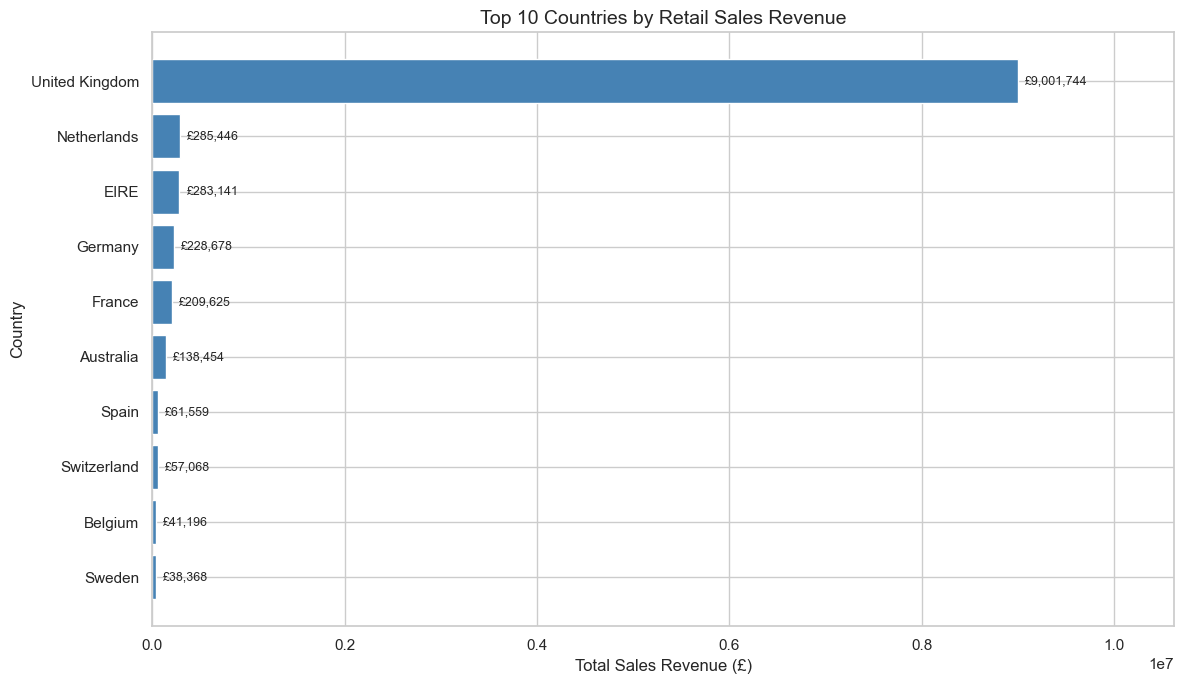

In [56]:
# STEP 69: Select the ten countries generating the highest revenue.
# The country_performance DataFrame was calculated in STEPS 65–68.

top_10_countries = country_performance.head(10).copy()


# STEP 70: Sort the countries in ascending revenue order.
# This positions the highest-revenue country at the top of the chart.

countries_plot = top_10_countries.sort_values(
    by="TotalRevenue",
    ascending=True
)


# STEP 71: Create a horizontal bar chart of revenue by country.
# Horizontal bars make country names and revenue comparisons clear.

plt.figure(figsize=(12, 7))

bars = plt.barh(
    countries_plot["Country"],
    countries_plot["TotalRevenue"],
    color="steelblue"
)

plt.title(
    "Top 10 Countries by Retail Sales Revenue",
    fontsize=14
)

plt.xlabel("Total Sales Revenue (£)")
plt.ylabel("Country")


# STEP 72: Add formatted revenue labels and display the chart.
# Use a percentage-based offset so labels work for large revenue values.

max_revenue = countries_plot["TotalRevenue"].max()

for bar in bars:
    revenue = bar.get_width()

    plt.text(
        revenue + max_revenue * 0.008,
        bar.get_y() + bar.get_height() / 2,
        f"£{revenue:,.0f}",
        va="center",
        fontsize=9
    )

plt.xlim(0, max_revenue * 1.18)
plt.tight_layout()
plt.show()

### International Sales Performance (Excluding the United Kingdom)

The United Kingdom accounts for approximately 84.59% of total
sales revenue, making smaller international markets difficult
to compare on the original chart.

To improve visibility, the following analysis excludes the
United Kingdom and compares the ten highest-revenue
international markets.

This allows international sales patterns to be examined
without changing the underlying dataset.

TOP 10 INTERNATIONAL MARKETS BY REVENUE


,Country,TotalRevenue,TotalOrders,AverageOrderValue,RevenueSharePct
1,Netherlands,"285,446.34",94,"3,036.66",2.68
2,EIRE,"283,140.52",288,983.13,2.66
3,Germany,"228,678.40",457,500.39,2.15
4,France,"209,625.37",392,534.76,1.97
5,Australia,"138,453.81",57,"2,429.01",1.30
6,Spain,"61,558.56",90,683.98,0.58
7,Switzerland,"57,067.60",54,"1,056.81",0.54
8,Belgium,"41,196.34",98,420.37,0.39
9,Sweden,"38,367.83",36,"1,065.77",0.36
10,Japan,"37,416.37",19,"1,969.28",0.35


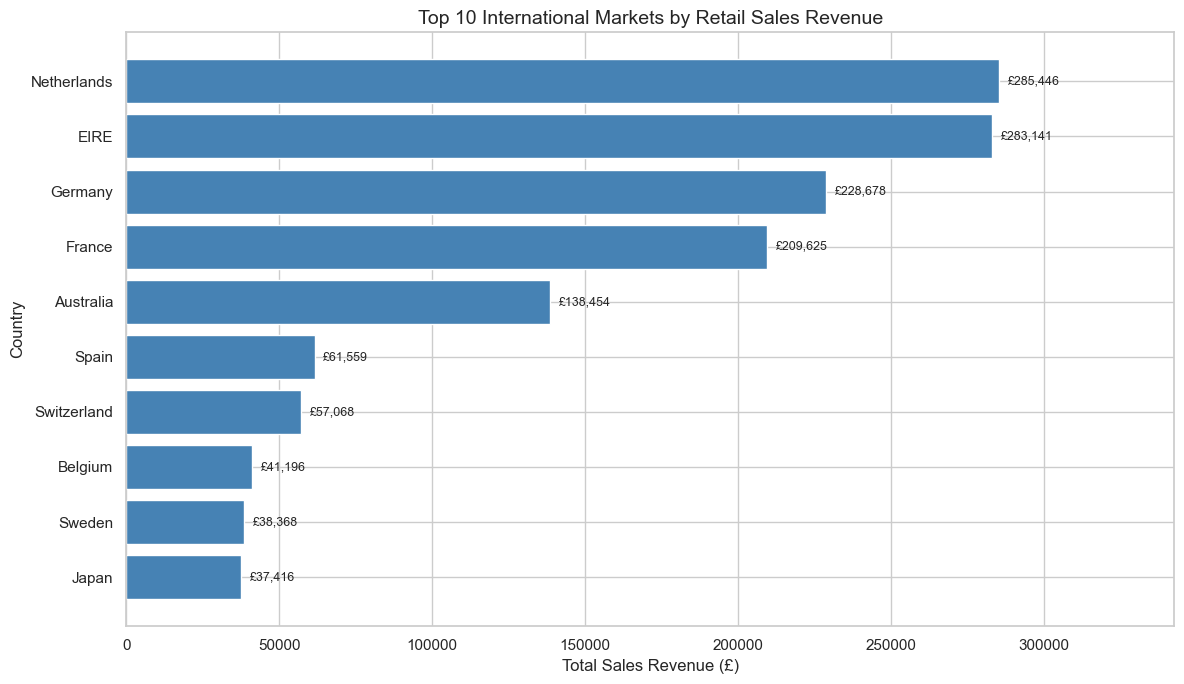

International market analysis validation: PASSED


In [57]:
# STEP 73: Filter out the United Kingdom from country performance.
# This allows smaller international markets to be compared clearly.

international_performance = country_performance.loc[
    country_performance["Country"] != "United Kingdom"
].copy()


# STEP 74: Identify the top 10 international markets by revenue.
# These rankings use the same valid-sales revenue definition.

top_10_international = (
    international_performance
    .sort_values("TotalRevenue", ascending=False)
    .head(10)
    .copy()
)

print("TOP 10 INTERNATIONAL MARKETS BY REVENUE")

display(
    top_10_international[
        [
            "Country",
            "TotalRevenue",
            "TotalOrders",
            "AverageOrderValue",
            "RevenueSharePct"
        ]
    ].round(2)
)


# STEP 75: Prepare the international markets for plotting.
# Ascending order places the highest-revenue market at the top.

international_plot = top_10_international.sort_values(
    "TotalRevenue",
    ascending=True
)


# STEP 76: Create a horizontal bar chart.
# Excluding the UK improves visibility of international differences.

plt.figure(figsize=(12, 7))

bars = plt.barh(
    international_plot["Country"],
    international_plot["TotalRevenue"],
    color="steelblue"
)

plt.title(
    "Top 10 International Markets by Retail Sales Revenue",
    fontsize=14
)

plt.xlabel("Total Sales Revenue (£)")
plt.ylabel("Country")


# STEP 77: Add revenue labels and validate the international analysis.
# Revenue labels make the chart easier for stakeholders to interpret.

max_revenue = international_plot["TotalRevenue"].max()

for bar in bars:
    revenue = bar.get_width()

    plt.text(
        revenue + max_revenue * 0.01,
        bar.get_y() + bar.get_height() / 2,
        f"£{revenue:,.0f}",
        va="center",
        fontsize=9
    )

plt.xlim(0, max_revenue * 1.20)
plt.tight_layout()
plt.show()

# Confirm that the UK was excluded.
assert "United Kingdom" not in top_10_international["Country"].values

# Confirm that exactly 10 international markets were selected.
assert len(top_10_international) == 10

# Confirm that international revenue is positive.
assert (top_10_international["TotalRevenue"] > 0).all()

print("International market analysis validation: PASSED")

### Geographic Sales Performance: Key Findings

The geographic analysis examined revenue across 38 countries using valid sales transactions from the Kaggle Online Retail Transactions Dataset.

**Key findings**

1. **UK market dominance:** The United Kingdom generated £9,001,744.09, representing 84.59% of total sales revenue. This indicates significant dependence on the domestic market.

2. **Leading international markets:** The Netherlands (£285,446.34), EIRE (£283,140.52), Germany (£228,678.40) and France (£209,625.37) were the highest-revenue international markets.

3. **Different purchasing patterns:** The Netherlands recorded a high average order value of £3,036.66 across 94 orders, while Germany generated £228,678.40 across 457 orders. This suggests that international revenue is driven by different combinations of order value and frequency.

**Business recommendations**

- Maintain strong inventory and customer service support for the UK market.
- Investigate purchasing patterns in the Netherlands and EIRE to understand large-order activity.
- Evaluate customer retention and marketing opportunities in Germany and France.

**Limitations**

These findings describe historical transactions from 2010–2011 and do not establish current market demand. Customer counts remain provisional because of the previously flagged customer identifier issue. Revenue also includes identified non-merchandise charges, so the figures represent valid-sales revenue rather than merchandise-only revenue.

## Customer Purchasing Behaviour Analysis

### Business Question 3: What are the purchasing patterns of retail customers?

This section examines customer purchasing frequency, spending
and order behaviour using the cleaned customer-analysis dataset.

CustomerID 15287 has been provisionally excluded from customer-level
analysis because its unusually high transaction frequency requires
further verification.

The analysis aims to:
- Calculate customer purchase frequency.
- Measure total spending and average order value per customer.
- Identify differences between frequent and occasional purchasers.
- Prepare customer-level features for subsequent RFM segmentation.

**Limitation:** Customer identifiers are treated as provisional.
Results should not be interpreted as independently verified
customer identities.

In [58]:
# STEP 78: Confirm that the provisional customer dataset is available.
# This dataset excludes the previously flagged CustomerID 15287.

assert "df_customer_sales" in globals(), (
    "Customer-analysis dataset not found. "
    "Check the variable name used in Notebook 02."
)

# STEP 79: Verify the customer-analysis dataset.
# Check that the flagged identifier is absent and revenue is positive.

assert (df_customer_sales["Revenue"] > 0).all()
assert (df_customer_sales["CustomerID"] != 15287).all()

print("Customer-analysis rows:", len(df_customer_sales))
print(
    "Provisional unique customers:",
    df_customer_sales["CustomerID"].nunique()
)


# STEP 80: Aggregate sales transactions at customer level.
# Each customer receives one record containing their purchasing metrics.

customer_performance = (
    df_customer_sales.groupby("CustomerID")
    .agg(
        TotalSpending=("Revenue", "sum"),
        TotalOrders=("InvoiceNo", "nunique"),
        TotalUnits=("Quantity", "sum"),
        FirstPurchase=("InvoiceDate", "min"),
        LastPurchase=("InvoiceDate", "max")
    )
    .reset_index()
)


# STEP 81: Calculate purchase frequency and average order value.
# Purchase frequency is the number of distinct orders per customer.
# Average order value measures spending per order.

customer_performance["PurchaseFrequency"] = (
    customer_performance["TotalOrders"]
)

customer_performance["AverageOrderValue"] = (
    customer_performance["TotalSpending"]
    / customer_performance["TotalOrders"]
)


# STEP 82: Validate and preview customer-level results.
# Customer spending must reconcile with the provisional dataset.

assert np.isclose(
    customer_performance["TotalSpending"].sum(),
    df_customer_sales["Revenue"].sum()
)

assert (
    customer_performance["TotalOrders"] > 0
).all()

assert (
    customer_performance["AverageOrderValue"] > 0
).all()

print("\nCUSTOMER PURCHASING PERFORMANCE")

display(customer_performance.head(10).round(2))

print("\nTotal provisional customers:", len(customer_performance))

print(
    "Total provisional customer revenue: £",
    round(customer_performance["TotalSpending"].sum(), 2)
)

print("\nCustomer purchasing validation: PASSED")

Customer-analysis rows: 392672
Provisional unique customers: 4337

CUSTOMER PURCHASING PERFORMANCE


,CustomerID,TotalSpending,TotalOrders,TotalUnits,FirstPurchase,LastPurchase,PurchaseFrequency,AverageOrderValue
0,12346,"77,183.60",1,74215,2011-01-18 10:01:00,2011-01-18 10:01:00,1,"77,183.60"
1,12347,"4,310.00",7,2458,2010-12-07 14:57:00,2011-12-07 15:52:00,7,615.71
2,12348,"1,797.24",4,2341,2010-12-16 19:09:00,2011-09-25 13:13:00,4,449.31
3,12349,"1,757.55",1,631,2011-11-21 09:51:00,2011-11-21 09:51:00,1,"1,757.55"
4,12350,334.40,1,197,2011-02-02 16:01:00,2011-02-02 16:01:00,1,334.40
5,12352,"2,506.04",8,536,2011-02-16 12:33:00,2011-11-03 14:37:00,8,313.26
6,12353,89.00,1,20,2011-05-19 17:47:00,2011-05-19 17:47:00,1,89.00
7,12354,"1,079.40",1,530,2011-04-21 13:11:00,2011-04-21 13:11:00,1,"1,079.40"
8,12355,459.40,1,240,2011-05-09 13:49:00,2011-05-09 13:49:00,1,459.40
9,12356,"2,811.43",3,1591,2011-01-18 09:50:00,2011-11-17 08:40:00,3,937.14



Total provisional customers: 4337
Total provisional customer revenue: £ 8886722.2

Customer purchasing validation: PASSED


### Customer Purchase Frequency and Repeat Purchasing

This analysis examines the number of distinct orders placed by each
provisional customer.

Customers are classified as:
- **One-Time Customer:** One recorded order.
- **Repeat Customer:** Two or more recorded orders.

These classifications apply only to the historical observation period.
They do not establish whether customers purchased before or after
the available dataset.

In [59]:
# STEP 83: Classify customers based on their recorded purchase frequency.
# Customers with one order are classified as one-time customers.
# Customers with two or more orders are classified as repeat customers.

customer_performance["CustomerType"] = np.where(
    customer_performance["PurchaseFrequency"] == 1,
    "One-Time Customer",
    "Repeat Customer"
)


# STEP 84: Summarise customers by purchasing category.
# Calculate the number of customers and their combined spending.

customer_type_summary = (
    customer_performance.groupby("CustomerType")
    .agg(
        NumberOfCustomers=("CustomerID", "nunique"),
        TotalSpending=("TotalSpending", "sum"),
        TotalOrders=("TotalOrders", "sum")
    )
    .reset_index()
)


# STEP 85: Calculate the percentage of customers in each category.
# This helps measure repeat purchasing within the observation period.

customer_type_summary["CustomerPercentage"] = (
    customer_type_summary["NumberOfCustomers"]
    / len(customer_performance) * 100
)

# Calculate each category's contribution to customer-attributed revenue.
customer_type_summary["RevenuePercentage"] = (
    customer_type_summary["TotalSpending"]
    / customer_performance["TotalSpending"].sum() * 100
)


# STEP 86: Validate the customer classification.
# Every provisional customer must belong to exactly one category.

assert (
    customer_type_summary["NumberOfCustomers"].sum()
    == len(customer_performance)
)

assert (
    customer_type_summary["TotalOrders"].sum()
    == customer_performance["TotalOrders"].sum()
)

assert np.isclose(
    customer_type_summary["TotalSpending"].sum(),
    customer_performance["TotalSpending"].sum()
)


# STEP 87: Display the purchasing behaviour summary.
# Round monetary values and percentages for readability.

print("CUSTOMER PURCHASING FREQUENCY SUMMARY")

display(customer_type_summary.round(2))

print("\nTotal provisional customers:", len(customer_performance))
print("Customer classification validation: PASSED")

CUSTOMER PURCHASING FREQUENCY SUMMARY


,CustomerType,NumberOfCustomers,TotalSpending,TotalOrders,CustomerPercentage,RevenuePercentage
0,One-Time Customer,1493,"613,989.56",1493,34.42,6.91
1,Repeat Customer,2844,"8,272,732.64",17037,65.58,93.09



Total provisional customers: 4337
Customer classification validation: PASSED


### Interpretation: Customer Purchase Frequency

The analysis identified 4,337 provisional customers.

- **One-time customers:** 1,493 (34.42%), contributing £613,989.56 (6.91%) of customer-attributed revenue.
- **Repeat customers:** 2,844 (65.58%), contributing £8,272,732.64 (93.09%) of customer-attributed revenue.

**Key insight:** Repeat customers account for the majority of customer-attributed revenue, indicating that existing customer relationships are important to historical retail performance.

**Business implication:** The retailer could investigate customer retention strategies, personalised marketing, and loyalty initiatives to encourage further repeat purchasing.

**Limitation:** CustomerID 15287 was excluded from the provisional customer analysis pending verification. Additionally, purchasing behaviour is observed only within the dataset's historical period.

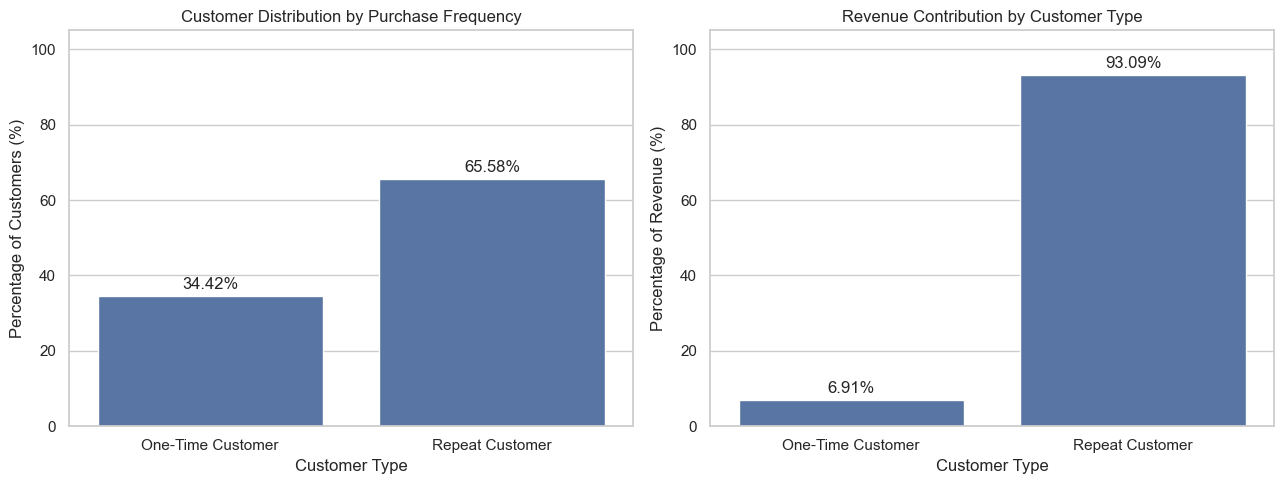

In [60]:
# STEP 88: Prepare the customer purchasing summary for visualisation.
# Use the existing validated summary to avoid recalculating metrics.

plot_data = customer_type_summary.copy()


# STEP 89: Create a two-panel comparison of customer percentages
# and revenue percentages.
# This highlights the importance of repeat customers.

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Chart 1: Percentage of customers by purchasing category.
sns.barplot(
    data=plot_data,
    x="CustomerType",
    y="CustomerPercentage",
    ax=axes[0]
)

axes[0].set_title("Customer Distribution by Purchase Frequency")
axes[0].set_xlabel("Customer Type")
axes[0].set_ylabel("Percentage of Customers (%)")
axes[0].set_ylim(0, 105)

# Add percentage labels above the bars.
for container in axes[0].containers:
    axes[0].bar_label(container, fmt="%.2f%%", padding=3)


# STEP 90: Visualise the revenue contribution of each customer group.
# Compare the proportion of revenue with the customer distribution.

sns.barplot(
    data=plot_data,
    x="CustomerType",
    y="RevenuePercentage",
    ax=axes[1]
)

axes[1].set_title("Revenue Contribution by Customer Type")
axes[1].set_xlabel("Customer Type")
axes[1].set_ylabel("Percentage of Revenue (%)")
axes[1].set_ylim(0, 105)

# Add percentage labels above the bars.
for container in axes[1].containers:
    axes[1].bar_label(container, fmt="%.2f%%", padding=3)


# STEP 91: Improve chart layout and display the visualisations.
# Tight layout prevents titles and labels from overlapping.

plt.tight_layout()
plt.show()

### Business Insight: Repeat Purchasing and Revenue

The analysis shows that repeat customers represent 65.58% of the
provisional customer base and contribute 93.09% of customer-attributed
revenue.

In contrast, one-time customers account for 34.42% of customers
but contribute only 6.91% of revenue.

**Business recommendation:** Investigate loyalty programmes,
personalised promotions and customer retention initiatives.

**Limitation:** These results exclude the flagged CustomerID 15287
and describe purchasing behaviour only within the historical dataset.